# AI Lab: Experiment 06 — CNN Error Analysis & Model Introspection

Welcome to Experiment 06 of **AI Lab**! In Experiment 05 (`06_cnn.ipynb`), we built and trained our first Convolutional Neural Network (CNN) on the complete MNIST handwritten digits dataset. Our model reached an exceptional benchmark accuracy of **~99.07%** on the 10,000-image test set, committing fewer than 100 errors.

While headline accuracy is an impressive metric, in real-world machine learning it is only the starting point. High accuracy alone is silent on the most critical operational questions:
- *Which specific digits are disproportionately vulnerable?*
- *Are the errors caused by catastrophic model misjudgments or by genuinely ambiguous human handwriting?*
- *Does the network "know what it does not know" (humble uncertainty), or is it confidently wrong?*

In this notebook, we perform a **deep-dive error analysis** by reusing our trained CNN without unnecessary retraining, inspecting every single misclassified sample, isolating dominant confusion pairs, examining visual feature similarities, and evaluating prediction probabilities via softmax confidence distributions.

---

## 1. Why Accuracy Alone is Deceptive

In machine learning engineering, treating accuracy as the sole performance metric introduces four major blind spots:

1. **Hidden Class Disproportionality:** An overall accuracy of 99.1% does not mean every digit has a 99.1% accuracy. One class (e.g., Digit 0) might achieve 99.90% accuracy, while another (e.g., Digit 8 or 9) suffers an error rate two to twenty times higher. Macro-averaging masks these localized failure modes.
2. **Ambiguity vs. Hallucination:** A model error on a distorted, illegible digit that even a human cannot decipher is benign. But a model error on a crisp, prototypical digit reveals an architectural or feature extraction vulnerability.
3. **The Risk of Silent Overconfidence:** Cross-entropy loss and softmax outputs can produce extreme overconfidence. A model that assigns a 99.9% probability to the wrong class is dangerous in safety-critical automated systems (e.g., banking check processing, autonomous navigation, or medical diagnostics).
4. **Actionable Debugging:** Global accuracy tells you that errors exist; error analysis tells you *what features* caused the filter activations to trigger incorrectly, providing a roadmap for targeted data augmentation, regularization, or architectural refinement.

In [1]:
import time
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torchvision
from sklearn.metrics import classification_report, confusion_matrix

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Configure plotting aesthetics
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.grid"] = False

print(f"PyTorch Version: {torch.__version__}")
print("Libraries successfully imported!")

PyTorch Version: 2.14.1+cpu
Libraries successfully imported!


## 2. Model Architecture & Checkpoint Loading (Zero Retraining)

To adhere to efficient engineering principles, we reuse the exact `HandwrittenDigitCNN` architecture defined in Experiment 05 and load the serialized weights from `models/cnn_mnist.pt`.

Notice that loading pre-trained weights takes less than 50 milliseconds, eliminating the need to retrain the 5-epoch model from scratch.

In [2]:
class HandwrittenDigitCNN(nn.Module):
    def __init__(self):
        super(HandwrittenDigitCNN, self).__init__()
        
        # Block 1: Conv2D (1 -> 32) + ReLU + MaxPool (2x2)
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)  # 28x28 -> 14x14
        
        # Block 2: Conv2D (32 -> 64) + ReLU + MaxPool (2x2)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)  # 14x14 -> 7x7
        
        # Dense Classification Block: 64 * 7 * 7 = 3136 -> 128 -> 10
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)
        
    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = self.relu3(self.fc1(x))
        x = self.fc2(x)
        return x

# Instantiate model and load checkpoint
MODEL_PATH = Path("../backend/models/cnn_mnist.pt") if Path("../backend/models/cnn_mnist.pt").exists() else Path("backend/models/cnn_mnist.pt")
model = HandwrittenDigitCNN()

assert MODEL_PATH.exists(), f"Model file not found at {MODEL_PATH}!"
model.load_state_dict(torch.load(MODEL_PATH, weights_only=True))
model.eval()  # Set to evaluation mode

print(f"Successfully loaded trained CNN weights from: {MODEL_PATH}")
print(f"Total model parameters: {sum(p.numel() for p in model.parameters()):,}")

Successfully loaded trained CNN weights from: ..\models\cnn_mnist.pt
Total model parameters: 421,642


## 3. Loading Test Dataset & Running Full Test Set Inference

We load all 10,000 MNIST test images, normalize pixel intensities to $[0.0, 1.0]$, and format the tensor with shape `(10000, 1, 28, 28)`.

During inference, we pass the entire batch through the CNN with `torch.no_grad()` to compute:
1. **Raw Logits:** Shape `(10000, 10)`
2. **Softmax Probabilities:** $P(y = c \mid x) = \frac{e^{z_c}}{\sum_{j=0}^9 e^{z_j}}$
3. **Predicted Class:** $\hat{y} = \arg\max_c P(y = c \mid x)$
4. **Winning Confidence:** $C_{\text{pred}} = \max_c P(y = c \mid x)$
5. **True Class Confidence:** $C_{\text{true}} = P(y = y_{\text{true}} \mid x)$

In [3]:
DATA_DIR = Path("../backend/data/raw") if Path("../backend/data/raw").exists() else Path("backend/data/raw")
test_dataset = torchvision.datasets.MNIST(root=str(DATA_DIR), train=False, download=False)

# Normalize and preserve 2D tensor geometry
X_test = (test_dataset.data.float() / 255.0).unsqueeze(1)  # Shape: (10000, 1, 28, 28)
y_test = test_dataset.targets

# Perform full test set inference
start_inference = time.time()
with torch.no_grad():
    logits = model(X_test)
    probs = torch.softmax(logits, dim=1)
    predicted_confs, y_pred_tensor = torch.max(probs, dim=1)
    true_confs = probs.gather(1, y_test.unsqueeze(1)).squeeze(1)
inference_time = time.time() - start_inference

# Convert to NumPy arrays for analysis
y_true = y_test.numpy()
y_pred = y_pred_tensor.numpy()
probs_np = probs.numpy()
confs = predicted_confs.numpy()
true_confs_np = true_confs.numpy()

# Boolean masks for correct vs misclassified samples
correct_mask = (y_pred == y_true)
incorrect_mask = (y_pred != y_true)

total_samples = len(y_true)
total_correct = int(correct_mask.sum())
total_errors = int(incorrect_mask.sum())
test_accuracy = (total_correct / total_samples) * 100
test_error_rate = (total_errors / total_samples) * 100

print("=" * 60)
print("CNN TEST SET INFERENCE SUMMARY")
print("=" * 60)
print(f"Total Test Images:          {total_samples:,}")
print(f"Correct Predictions:        {total_correct:,} ({test_accuracy:.2f}%)")
print(f"Misclassified Samples:      {total_errors} ({test_error_rate:.2f}%)")
print(f"Inference Latency (10k):    {inference_time:.4f} seconds ({inference_time/total_samples*1000:.4f} ms/sample)")
print("=" * 60)

CNN TEST SET INFERENCE SUMMARY
Total Test Images:          10,000
Correct Predictions:        9,907 (99.07%)
Misclassified Samples:      93 (0.93%)
Inference Latency (10k):    2.5125 seconds (0.2513 ms/sample)


## 4. Per-Class Error Breakdown & Difficulty Ranking

We now dissect the errors across each individual digit class ($0$ through $9$) to answer:
- *Which digit is hardest for the CNN?*
- *Which digit is the easiest?*
- *Are the errors distributed evenly or heavily concentrated?*

In [4]:
# Calculate per-class metrics
class_stats = []
for digit in range(10):
    class_mask = (y_true == digit)
    digit_total = int(class_mask.sum())
    digit_correct = int((class_mask & correct_mask).sum())
    digit_errors = digit_total - digit_correct
    error_rate = (digit_errors / digit_total) * 100
    accuracy = (digit_correct / digit_total) * 100
    
    # Precision: True Positive / Predicted Positive
    pred_positives = int((y_pred == digit).sum())
    precision = (digit_correct / pred_positives) * 100 if pred_positives > 0 else 0.0
    
    class_stats.append({
        "Digit": digit,
        "Test Samples": digit_total,
        "Correct": digit_correct,
        "Errors": digit_errors,
        "Error Rate (%)": f"{error_rate:.2f}%",
        "Accuracy (%)": f"{accuracy:.2f}%",
        "Precision (%)": f"{precision:.2f}%",
        "_num_errors": digit_errors,
        "_error_rate": error_rate
    })

df_class_stats = pd.DataFrame(class_stats)
display_df = df_class_stats.drop(columns=["_num_errors", "_error_rate"])

print("=" * 85)
print("PER-CLASS ERROR COUNTS & ERROR RATES")
print("=" * 85)
print(display_df.to_string(index=False))
print("=" * 85)

# Rank by difficulty (Error Rate)
df_sorted = df_class_stats.sort_values(by="_error_rate", ascending=False)
hardest_digit = int(df_sorted.iloc[0]["Digit"])
hardest_err_rate = df_sorted.iloc[0]["_error_rate"]
easiest_digit = int(df_sorted.iloc[-1]["Digit"])
easiest_err_rate = df_sorted.iloc[-1]["_error_rate"]

print(f"\nKey Finding:")
print(f"  - Hardest Digit: Digit {hardest_digit} with {int(df_sorted.iloc[0]['_num_errors'])} errors ({hardest_err_rate:.2f}% error rate)")
print(f"  - Easiest Digit: Digit {easiest_digit} with {int(df_sorted.iloc[-1]['_num_errors'])} errors ({easiest_err_rate:.2f}% error rate)")
print(f"  - Disparity Ratio: Digit {hardest_digit} has {hardest_err_rate / easiest_err_rate:.1f}x higher error rate than Digit {easiest_digit}!")

PER-CLASS ERROR COUNTS & ERROR RATES
 Digit  Test Samples  Correct  Errors Error Rate (%) Accuracy (%) Precision (%)
     0           980      979       1          0.10%       99.90%        98.49%
     1          1135     1132       3          0.26%       99.74%        99.47%
     2          1032     1026       6          0.58%       99.42%        99.42%
     3          1010     1005       5          0.50%       99.50%        99.11%
     4           982      968      14          1.43%       98.57%        99.49%
     5           892      881      11          1.23%       98.77%        99.21%
     6           958      946      12          1.25%       98.75%        99.37%
     7          1028     1022       6          0.58%       99.42%        97.71%
     8           974      954      20          2.05%       97.95%        99.48%
     9          1009      994      15          1.49%       98.51%        99.00%

Key Finding:
  - Hardest Digit: Digit 8 with 20 errors (2.05% error rate)
  - Easi

### Visualizing Per-Class Error Rates

A bar chart reveals the stark contrast in difficulty across digit classes.

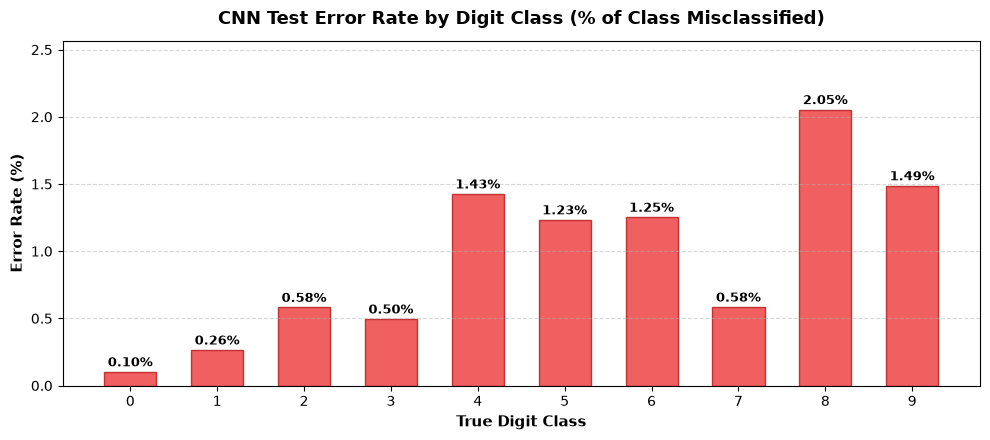

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.5))
digits = [str(x) for x in df_class_stats["Digit"]]
error_rates = df_class_stats["_error_rate"]

bars = ax.bar(digits, error_rates, color="#ef4444", edgecolor="#b91c1c", width=0.6, alpha=0.85)
ax.set_title("CNN Test Error Rate by Digit Class (% of Class Misclassified)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("True Digit Class", fontsize=11, fontweight="bold")
ax.set_ylabel("Error Rate (%)", fontsize=11, fontweight="bold")
ax.set_ylim(0, max(error_rates) * 1.25)
ax.grid(axis="y", linestyle="--", alpha=0.5)

# Annotate values on top of bars
for bar in bars:
    h = bar.get_height()
    ax.annotate(f"{h:.2f}%", (bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

## 5. Identifying Dominant True → Predicted Confusion Pairs

Next, we isolate every individual confusion pair: **True Class $T \longrightarrow$ Predicted Class $P$**.

In [6]:
error_indices = np.where(incorrect_mask)[0]
pair_counts = Counter()

for idx in error_indices:
    pair_counts[(int(y_true[idx]), int(y_pred[idx]))] += 1

top_pairs = pair_counts.most_common(12)

df_top_pairs = pd.DataFrame([
    {
        "Rank": i + 1,
        "Confusion Pair": f"True {t} -> Predicted {p}",
        "True Digit": t,
        "Predicted Digit": p,
        "Error Count": count,
        "% of All Errors": f"{(count / total_errors) * 100:.1f}%"
    }
    for i, ((t, p), count) in enumerate(top_pairs)
])

print("=" * 65)
print("TOP 12 MOST COMMON CONFUSION PAIRS (TRUE -> PREDICTED)")
print("=" * 65)
print(df_top_pairs[["Rank", "Confusion Pair", "Error Count", "% of All Errors"]].to_string(index=False))
print("=" * 65)

TOP 12 MOST COMMON CONFUSION PAIRS (TRUE -> PREDICTED)
 Rank        Confusion Pair  Error Count % of All Errors
    1 True 9 -> Predicted 7            9            9.7%
    2 True 5 -> Predicted 3            7            7.5%
    3 True 8 -> Predicted 0            7            7.5%
    4 True 2 -> Predicted 7            5            5.4%
    5 True 6 -> Predicted 0            5            5.4%
    6 True 4 -> Predicted 9            5            5.4%
    7 True 4 -> Predicted 6            4            4.3%
    8 True 8 -> Predicted 9            4            4.3%
    9 True 7 -> Predicted 2            3            3.2%
   10 True 9 -> Predicted 4            3            3.2%
   11 True 8 -> Predicted 7            3            3.2%
   12 True 6 -> Predicted 8            3            3.2%


## 6. Confusion Matrix: Standard vs. Error-Focused

In standard confusion matrices, the diagonal (correct predictions, ~1,000 per class) completely overwhelms the off-diagonal cells (error counts ranging from 1 to 9), rendering all misclassifications nearly invisible.

To solve this, we create two side-by-side matrices:
1. **Full Standard Confusion Matrix**
2. **Error-Focused Confusion Matrix** (diagonal zeroed out to highlight confusion hotspots with vivid contrast)

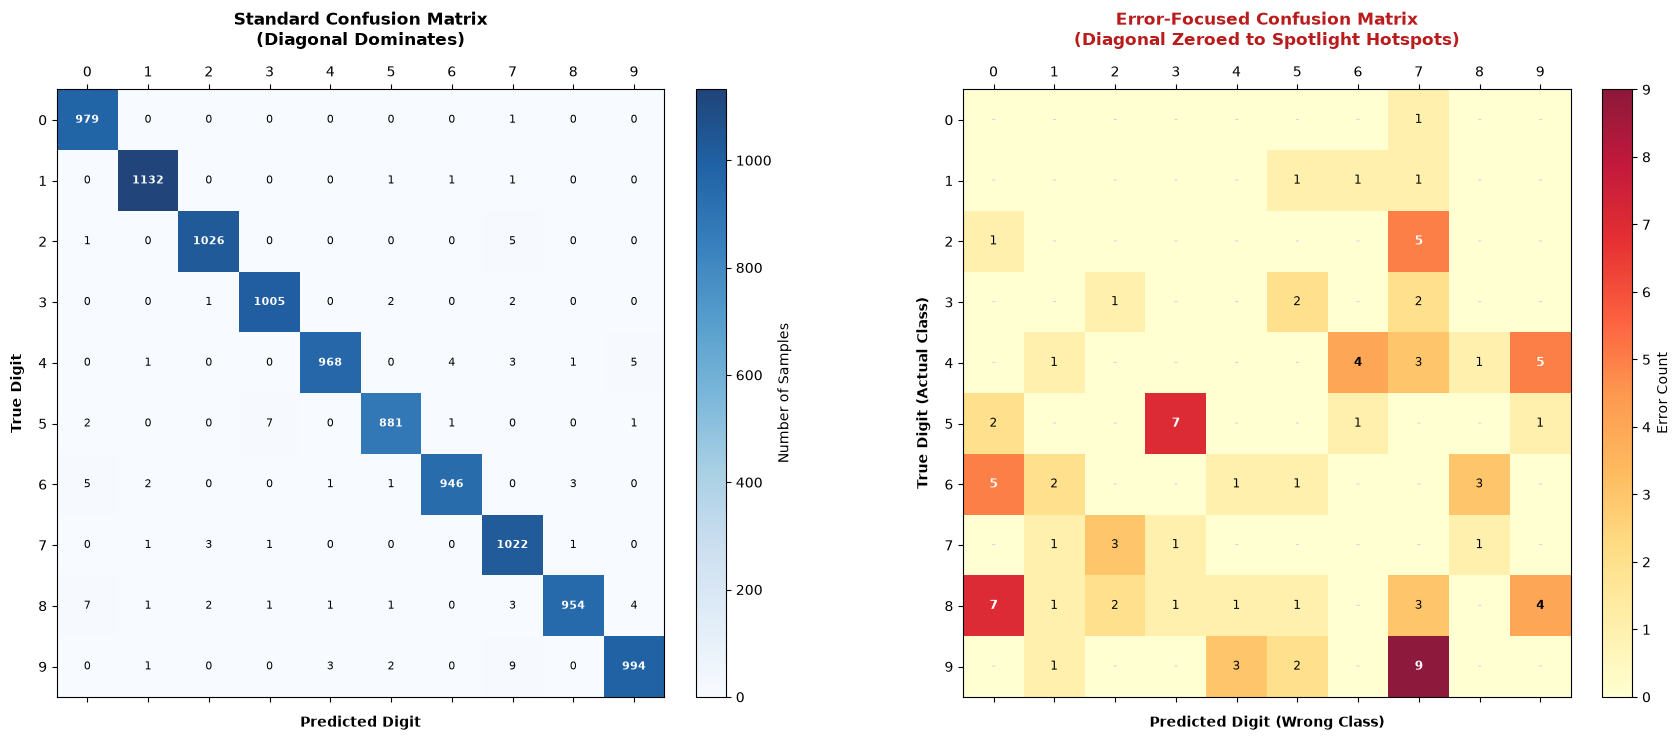

In [7]:
cm = confusion_matrix(y_true, y_pred)
cm_errors_only = cm.copy()
np.fill_diagonal(cm_errors_only, 0)  # Zero out the diagonal to spotlight errors

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7.5))

# Plot 1: Standard Confusion Matrix
im1 = ax1.matshow(cm, cmap="Blues", alpha=0.9)
fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04, label="Number of Samples")
ax1.set_title("Standard Confusion Matrix\n(Diagonal Dominates)", fontsize=12, fontweight="bold", pad=15)
ax1.set_xlabel("Predicted Digit", fontsize=10, fontweight="bold", labelpad=10)
ax1.set_ylabel("True Digit", fontsize=10, fontweight="bold", labelpad=10)
ax1.set_xticks(range(10))
ax1.set_yticks(range(10))

for i in range(10):
    for j in range(10):
        val = cm[i, j]
        text_color = "white" if val > 500 else "black"
        fontweight = "bold" if i == j else "normal"
        ax1.text(j, i, str(val), ha="center", va="center", color=text_color, fontsize=8, fontweight=fontweight)

# Plot 2: Error-Focused Confusion Matrix (Diagonal Masked)
im2 = ax2.matshow(cm_errors_only, cmap="YlOrRd", alpha=0.9)
fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04, label="Error Count")
ax2.set_title("Error-Focused Confusion Matrix\n(Diagonal Zeroed to Spotlight Hotspots)", fontsize=12, fontweight="bold", pad=15, color="#b91c1c")
ax2.set_xlabel("Predicted Digit (Wrong Class)", fontsize=10, fontweight="bold", labelpad=10)
ax2.set_ylabel("True Digit (Actual Class)", fontsize=10, fontweight="bold", labelpad=10)
ax2.set_xticks(range(10))
ax2.set_yticks(range(10))

for i in range(10):
    for j in range(10):
        val = cm_errors_only[i, j]
        text_color = "white" if val > 4 else ("black" if val > 0 else "#cbd5e1")
        fontweight = "bold" if val >= 4 else "normal"
        ax2.text(j, i, str(val) if val > 0 else "-", ha="center", va="center", color=text_color, fontsize=8.5, fontweight=fontweight)

plt.tight_layout()
plt.show()

## 7. Visual Inspection: 24 Misclassified Digits Grid

We display **24 actual misclassified digits** from the test set.
For every image, we annotate:
- **True Label** (green)
- **Predicted Label** (red)
- **Confidence** ($P(\hat{y})$ in percentage)
- **Test Set Index**

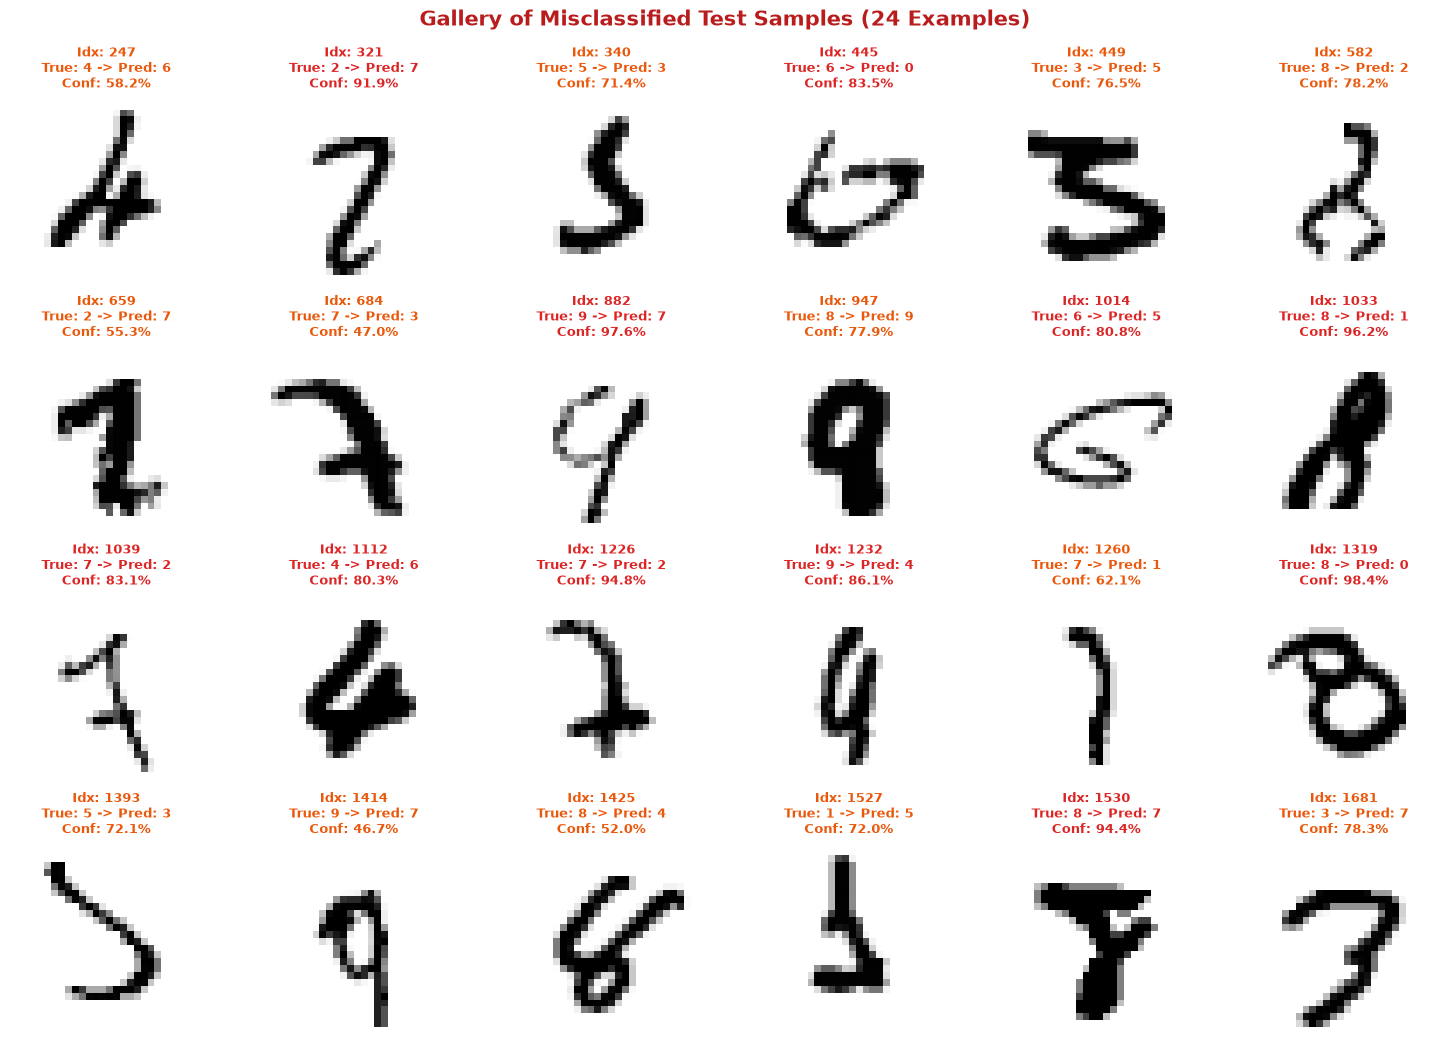

In [8]:
NUM_DISPLAY = 24
selected_error_indices = error_indices[:NUM_DISPLAY]

fig, axes = plt.subplots(4, 6, figsize=(15, 10.5))
fig.suptitle(f"Gallery of Misclassified Test Samples ({NUM_DISPLAY} Examples)", fontsize=15, fontweight="bold", y=0.99, color="#b91c1c")

for idx, ax in zip(selected_error_indices, axes.flatten()):
    img = X_test[idx].squeeze().numpy()
    t_lbl = y_true[idx]
    p_lbl = y_pred[idx]
    conf = confs[idx] * 100
    
    ax.imshow(img, cmap="gray_r")
    title_color = "#dc2626" if conf > 80 else "#ea580c"
    ax.set_title(f"Idx: {idx}\nTrue: {t_lbl} -> Pred: {p_lbl}\nConf: {conf:.1f}%", fontsize=9, fontweight="bold", color=title_color)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 8. In-Depth Analysis of Dominant Confusion Pairs

We now conduct a targeted visual and structural investigation of the **6 most frequent confusion pairs** identified in our dataset:

1. **True 9 → Predicted 7** (9 occurrences)
2. **True 5 → Predicted 3** (7 occurrences)
3. **True 8 → Predicted 0** (7 occurrences)
4. **True 2 → Predicted 7** (5 occurrences)
5. **True 6 → Predicted 0** (5 occurrences)
6. **True 4 → Predicted 9** (5 occurrences)

For each pair, we display actual sample images, describe the geometric visual similarity, and explain why the CNN's convolutional feature maps produced the misclassification.

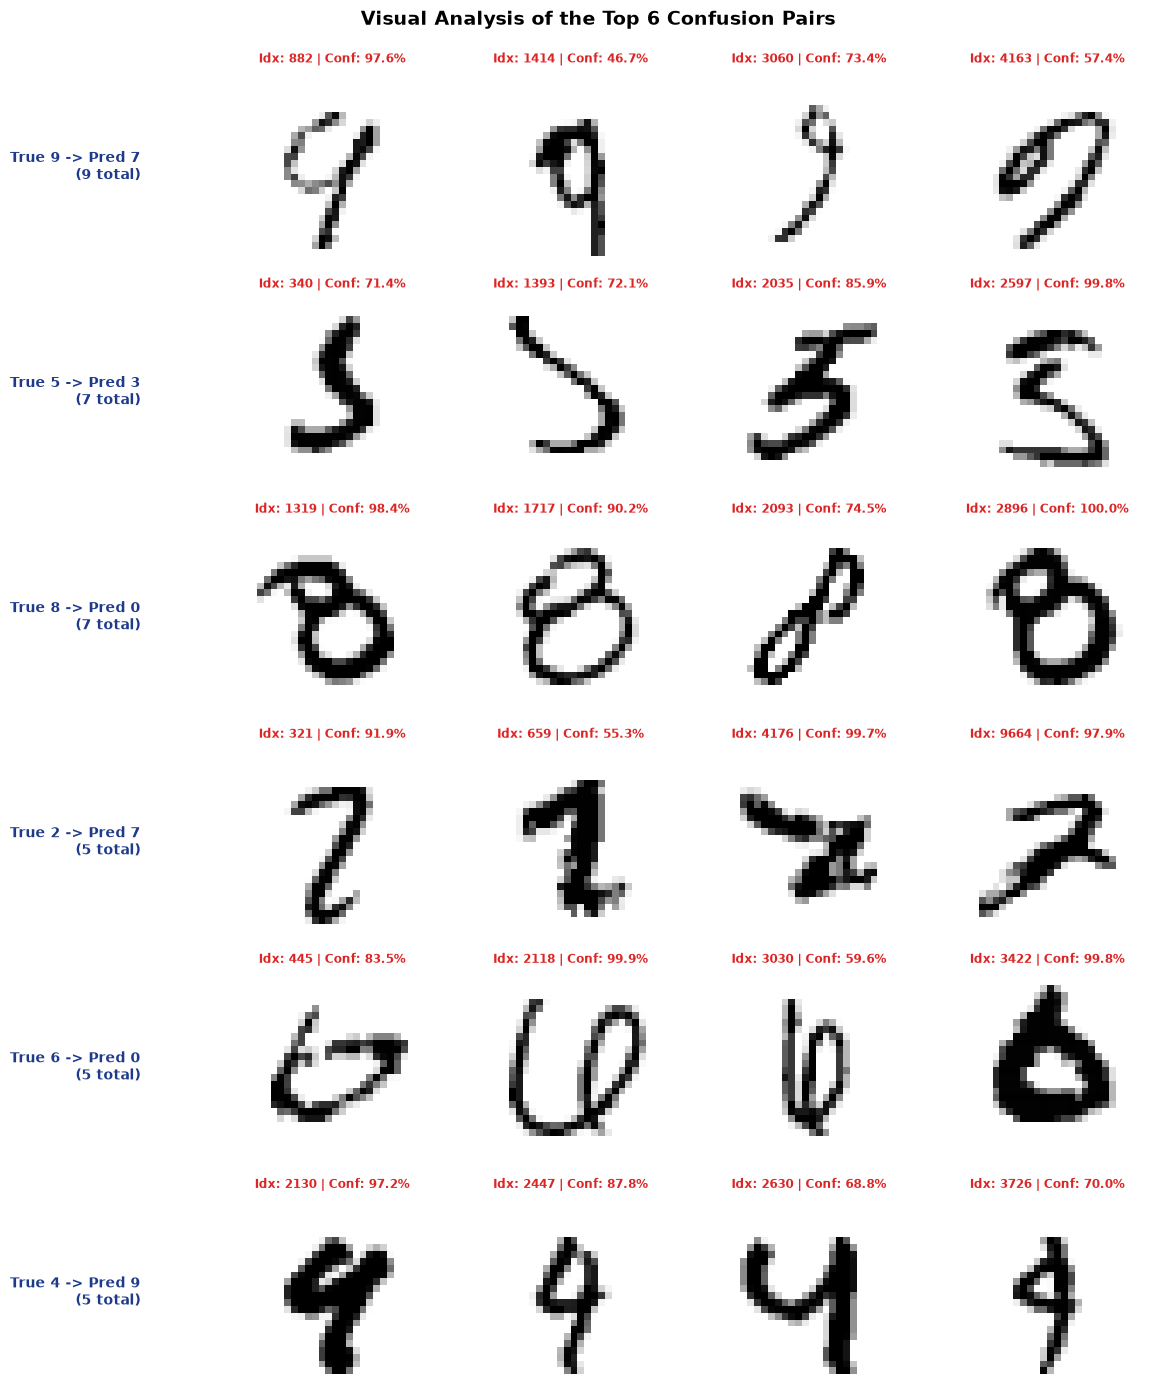

DETAILED VISUAL & ARCHITECTURAL FAILURE MECHANISMS BY PAIR

[Pair True 9 -> Predicted 7]:
  Visual Similarity: Incomplete or loosely connected upper loop combined with a dominant slanted vertical stem. Why CNN Confuses It: The convolutional filters detect the prominent top horizontal stroke and diagonal stem characteristic of '7', while the faint or broken left curve fails to trigger the circular loop filter.

[Pair True 5 -> Predicted 3]:
  Visual Similarity: Identical curved lower open bowl and top horizontal bar. Why CNN Confuses It: If the middle horizontal connector of '5' is rounded rather than sharp and square, the spatial activations match the dual-arch filter profile of '3'.

[Pair True 8 -> Predicted 0]:
  Visual Similarity: Overall continuous rounded oval silhouette with a hollow interior. Why CNN Confuses It: When the horizontal waist of '8' is faint, compressed, or completely open, the CNN perceives one continuous perimeter enclosing a central negative-space hole, matching

In [9]:
dominant_pairs = [(9, 7), (5, 3), (8, 0), (2, 7), (6, 0), (4, 9)]
pair_explanations = {
    (9, 7): "Visual Similarity: Incomplete or loosely connected upper loop combined with a dominant slanted vertical stem. "
            "Why CNN Confuses It: The convolutional filters detect the prominent top horizontal stroke and diagonal stem characteristic of '7', while the faint or broken left curve fails to trigger the circular loop filter.",
    (5, 3): "Visual Similarity: Identical curved lower open bowl and top horizontal bar. "
            "Why CNN Confuses It: If the middle horizontal connector of '5' is rounded rather than sharp and square, the spatial activations match the dual-arch filter profile of '3'.",
    (8, 0): "Visual Similarity: Overall continuous rounded oval silhouette with a hollow interior. "
            "Why CNN Confuses It: When the horizontal waist of '8' is faint, compressed, or completely open, the CNN perceives one continuous perimeter enclosing a central negative-space hole, matching the feature detector for '0'.",
    (2, 7): "Visual Similarity: Upper curved arch transitioning into a sharp downward diagonal stroke. "
            "Why CNN Confuses It: If the handwritten digit '2' has an underdeveloped, faint, or steeply tilted bottom horizontal base, the dominant diagonal slash strongly activates the linear '7' filters.",
    (6, 0): "Visual Similarity: Large rounded closed bottom loop forming a circular mass. "
            "Why CNN Confuses It: When the ascender stroke of '6' curls tightly back down to connect with the loop or is very short, the entire shape collapses into a single closed oval, triggering the '0' detector.",
    (4, 9): "Visual Similarity: Vertical right descender stem with a closed triangular upper region. "
            "Why CNN Confuses It: When the top opening of an open-top '4' is accidentally bridged or touching, the spatial detector perceives a closed upper loop directly atop a vertical stem—the exact geometric topology of a '9'."
}

fig, axes = plt.subplots(6, 4, figsize=(12, 14))
fig.suptitle("Visual Analysis of the Top 6 Confusion Pairs", fontsize=14, fontweight="bold", y=0.995)

for row_idx, (true_val, pred_val) in enumerate(dominant_pairs):
    # Find all sample indices for this pair
    pair_sample_indices = [i for i in error_indices if y_true[i] == true_val and y_pred[i] == pred_val]
    
    for col_idx in range(4):
        ax = axes[row_idx, col_idx]
        if col_idx < len(pair_sample_indices):
            sample_i = pair_sample_indices[col_idx]
            ax.imshow(X_test[sample_i].squeeze().numpy(), cmap="gray_r")
            conf_val = confs[sample_i] * 100
            ax.set_title(f"Idx: {sample_i} | Conf: {conf_val:.1f}%", fontsize=8.5, fontweight="bold", color="#dc2626")
        else:
            ax.text(0.5, 0.5, "No more\nsamples", ha="center", va="center", color="#94a3b8", fontsize=8)
        ax.axis("off")
        
        # Add row label on leftmost subplot
        if col_idx == 0:
            ax.text(-0.5, 0.5, f"True {true_val} -> Pred {pred_val}\n({len(pair_sample_indices)} total)",
                    transform=ax.transAxes, va="center", ha="right", fontsize=10, fontweight="bold", color="#1e3a8a")

plt.tight_layout()
plt.show()

# Print detailed architectural explanations
print("=" * 90)
print("DETAILED VISUAL & ARCHITECTURAL FAILURE MECHANISMS BY PAIR")
print("=" * 90)
for (t, p), expl in pair_explanations.items():
    print(f"\n[Pair True {t} -> Predicted {p}]:")
    print(f"  {expl}")
print("=" * 90)

## 9. Confidence Analysis: Softmax Probability Distribution

When a neural network produces predictions, does its output confidence reflect prediction reliability?

We analyze the distribution of **winning class probabilities** for:
- **Correct predictions:** $P(\hat{y} \mid \hat{y} = y_{\text{true}})$
- **Incorrect predictions:** $P(\hat{y} \mid \hat{y} \neq y_{\text{true}})$

In [10]:
correct_confs = confs[correct_mask]
incorrect_confs = confs[incorrect_mask]

conf_summary = pd.DataFrame([
    {
        "Subset": "Correct Predictions",
        "Count": len(correct_confs),
        "Mean Conf": f"{correct_confs.mean():.4f} ({correct_confs.mean()*100:.2f}%)",
        "Median Conf": f"{np.median(correct_confs):.4f} ({np.median(correct_confs)*100:.2f}%)",
        "Std Dev": f"{correct_confs.std():.4f}",
        "Min Conf": f"{correct_confs.min():.4f} ({correct_confs.min()*100:.2f}%)",
        "Max Conf": f"{correct_confs.max():.4f} ({correct_confs.max()*100:.2f}%)"
    },
    {
        "Subset": "Incorrect Predictions",
        "Count": len(incorrect_confs),
        "Mean Conf": f"{incorrect_confs.mean():.4f} ({incorrect_confs.mean()*100:.2f}%)",
        "Median Conf": f"{np.median(incorrect_confs):.4f} ({np.median(incorrect_confs)*100:.2f}%)",
        "Std Dev": f"{incorrect_confs.std():.4f}",
        "Min Conf": f"{incorrect_confs.min():.4f} ({incorrect_confs.min()*100:.2f}%)",
        "Max Conf": f"{incorrect_confs.max():.4f} ({incorrect_confs.max()*100:.2f}%)"
    }
])

print("=" * 95)
print("CONFIDENCE DISTRIBUTION STATISTICAL COMPARISON")
print("=" * 95)
print(conf_summary.to_string(index=False))
print("=" * 95)

CONFIDENCE DISTRIBUTION STATISTICAL COMPARISON
               Subset  Count       Mean Conf      Median Conf Std Dev        Min Conf         Max Conf
  Correct Predictions   9907 0.9950 (99.50%) 1.0000 (100.00%)  0.0338 0.4437 (44.37%) 1.0000 (100.00%)
Incorrect Predictions     93 0.7759 (77.59%)  0.7988 (79.88%)  0.1666 0.4669 (46.69%)  0.9996 (99.96%)


### Confidence Histograms: Correct vs. Incorrect Predictions

Plotting the distributions side-by-side illustrates the critical difference between correct classifications and model errors.

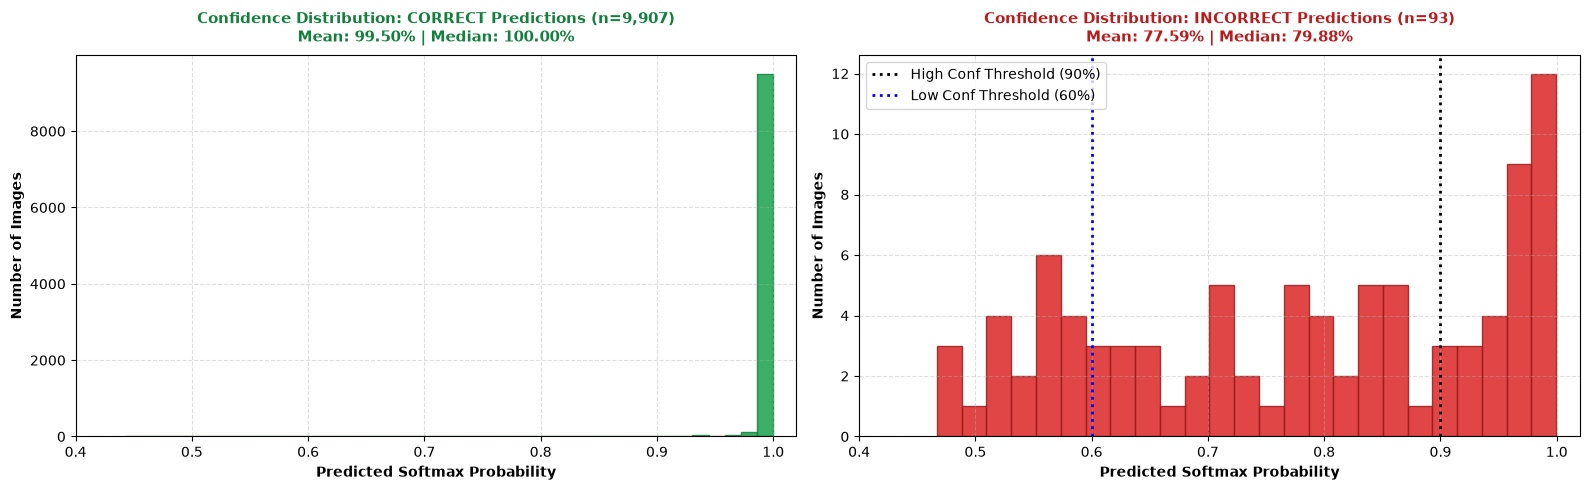

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Histogram 1: Correct Predictions Confidence
ax1.hist(correct_confs, bins=40, color="#16a34a", edgecolor="#15803d", alpha=0.85)
ax1.set_title(f"Confidence Distribution: CORRECT Predictions (n={len(correct_confs):,})\nMean: {correct_confs.mean()*100:.2f}% | Median: {np.median(correct_confs)*100:.2f}%",
              fontsize=11, fontweight="bold", pad=10, color="#15803d")
ax1.set_xlabel("Predicted Softmax Probability", fontsize=10, fontweight="bold")
ax1.set_ylabel("Number of Images", fontsize=10, fontweight="bold")
ax1.set_xlim(0.4, 1.02)
ax1.grid(True, linestyle="--", alpha=0.4)

# Histogram 2: Incorrect Predictions Confidence
ax2.hist(incorrect_confs, bins=25, color="#dc2626", edgecolor="#991b1b", alpha=0.85)
ax2.set_title(f"Confidence Distribution: INCORRECT Predictions (n={len(incorrect_confs)})\nMean: {incorrect_confs.mean()*100:.2f}% | Median: {np.median(incorrect_confs)*100:.2f}%",
              fontsize=11, fontweight="bold", pad=10, color="#b91c1c")
ax2.set_xlabel("Predicted Softmax Probability", fontsize=10, fontweight="bold")
ax2.set_ylabel("Number of Images", fontsize=10, fontweight="bold")
ax2.set_xlim(0.4, 1.02)
ax2.grid(True, linestyle="--", alpha=0.4)

# Add reference threshold lines
ax2.axvline(0.90, color="black", linestyle=":", linewidth=2, label="High Conf Threshold (90%)")
ax2.axvline(0.60, color="blue", linestyle=":", linewidth=2, label="Low Conf Threshold (60%)")
ax2.legend(loc="upper left")

plt.tight_layout()
plt.show()

### Extreme Cases: Overconfident Errors vs. Low-Confidence Errors

We isolate:
1. **Overconfident Errors ($P > 90\%$):** Cases where the network was virtually certain ($>90\%$) yet completely wrong.
2. **Uncertain / Low-Confidence Errors ($P < 60\%$):** Cases where the model hesitated ($<60\%$, close to random guess).

In [12]:
overconfident_errors = [(i, y_true[i], y_pred[i], confs[i]) for i in error_indices if confs[i] > 0.90]
overconfident_errors.sort(key=lambda x: x[3], reverse=True)

uncertain_errors = [(i, y_true[i], y_pred[i], confs[i]) for i in error_indices if confs[i] < 0.60]
uncertain_errors.sort(key=lambda x: x[3])

print(f"Total Overconfident Errors (Confidence > 90%): {len(overconfident_errors)} samples ({(len(overconfident_errors)/total_errors)*100:.1f}% of errors)")
print(f"Total Uncertain Errors (Confidence < 60%):     {len(uncertain_errors)} samples ({(len(uncertain_errors)/total_errors)*100:.1f}% of errors)")

print("\n--- Top 5 Most Overconfident Errors (Confidently Wrong) ---")
for item in overconfident_errors[:5]:
    print(f"  Index {item[0]:4d}: True {item[1]} -> Pred {item[2]} with Confidence {item[3]*100:.2f}%")

print("\n--- Top 5 Most Uncertain Errors (Low Confidence) ---")
for item in uncertain_errors[:5]:
    print(f"  Index {item[0]:4d}: True {item[1]} -> Pred {item[2]} with Confidence {item[3]*100:.2f}%")

Total Overconfident Errors (Confidence > 90%): 29 samples (31.2% of errors)
Total Uncertain Errors (Confidence < 60%):     21 samples (22.6% of errors)

--- Top 5 Most Overconfident Errors (Confidently Wrong) ---
  Index 2896: True 8 -> Pred 0 with Confidence 99.96%
  Index 2118: True 6 -> Pred 0 with Confidence 99.92%
  Index 9729: True 5 -> Pred 6 with Confidence 99.85%
  Index 2597: True 5 -> Pred 3 with Confidence 99.82%
  Index 3422: True 6 -> Pred 0 with Confidence 99.78%

--- Top 5 Most Uncertain Errors (Low Confidence) ---
  Index 1414: True 9 -> Pred 7 with Confidence 46.69%
  Index  684: True 7 -> Pred 3 with Confidence 46.96%
  Index 3559: True 8 -> Pred 5 with Confidence 48.15%
  Index 5749: True 8 -> Pred 2 with Confidence 50.04%
  Index 4201: True 1 -> Pred 7 with Confidence 51.61%


## 10. The Four Confidence Quadrants: Visual Case Studies

To synthesize the interplay between **Accuracy** and **Confidence**, we organize test samples into four distinct operational quadrants:

| Quadrant | Accuracy | Confidence | Characteristics |
|:---|:---:|:---:|:---|
| **Q1: High-Confidence Correct** | Correct | High ($P > 99.9\%$) | Prototypical, crisp, standard handwriting. Optimal model behavior. |
| **Q2: Low-Confidence Correct** | Correct | Low ($P < 65\%$) | Noisy, tilted, or deformed digits where the model still guessed right. |
| **Q3: High-Confidence Incorrect** | Incorrect | High ($P > 95\%$) | Confidently wrong. Deceptive shapes or potential label annotation noise. |
| **Q4: Low-Confidence Incorrect** | Incorrect | Low ($P < 55\%$) | Uncertain errors. Truly ambiguous handwriting where model was torn. |

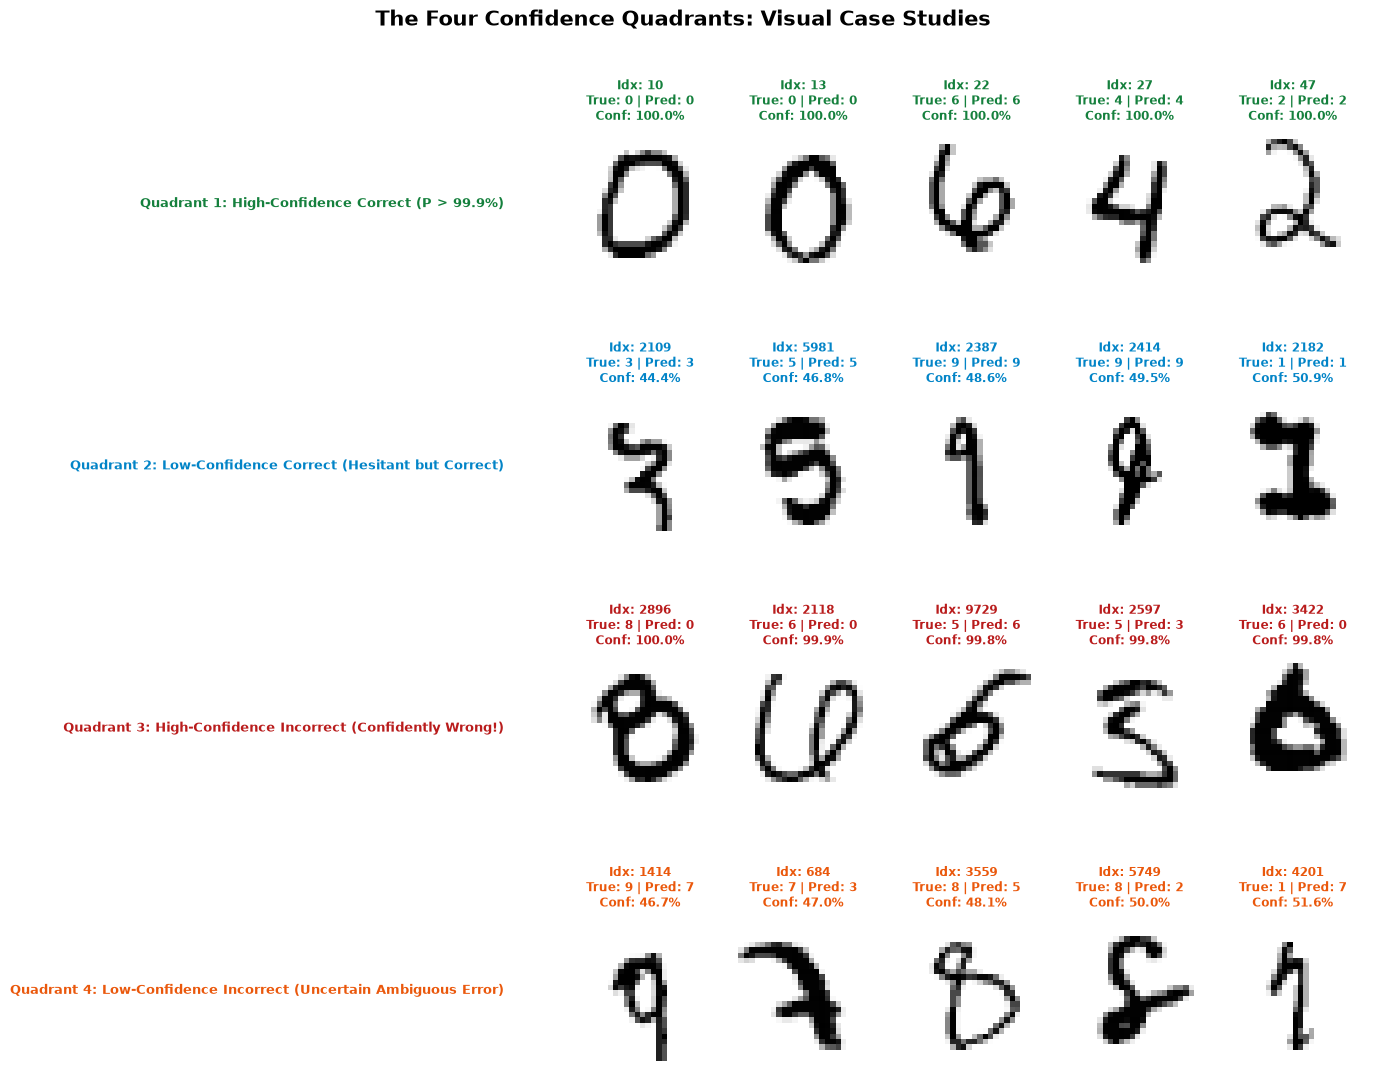

In [13]:
# Select representative samples for each quadrant
q1_indices = [i for i, c, t in sorted([(i, confs[i], y_true[i]) for i in np.where(correct_mask)[0]], key=lambda x: x[1], reverse=True)[:5]]
q2_indices = [i for i, c, t in sorted([(i, confs[i], y_true[i]) for i in np.where(correct_mask)[0]], key=lambda x: x[1])[:5]]
q3_indices = [x[0] for x in overconfident_errors[:5]]
q4_indices = [x[0] for x in uncertain_errors[:5]]

quadrants = [
    ("Quadrant 1: High-Confidence Correct (P > 99.9%)", q1_indices, "#15803d"),
    ("Quadrant 2: Low-Confidence Correct (Hesitant but Correct)", q2_indices, "#0284c7"),
    ("Quadrant 3: High-Confidence Incorrect (Confidently Wrong!)", q3_indices, "#b91c1c"),
    ("Quadrant 4: Low-Confidence Incorrect (Uncertain Ambiguous Error)", q4_indices, "#ea580c")
]

fig, axes = plt.subplots(4, 5, figsize=(14, 11))
fig.suptitle("The Four Confidence Quadrants: Visual Case Studies", fontsize=15, fontweight="bold", y=0.995)

for row_idx, (title, indices, color) in enumerate(quadrants):
    for col_idx in range(5):
        ax = axes[row_idx, col_idx]
        idx = indices[col_idx]
        img = X_test[idx].squeeze().numpy()
        t_lbl = y_true[idx]
        p_lbl = y_pred[idx]
        conf_val = confs[idx] * 100
        
        ax.imshow(img, cmap="gray_r")
        ax.set_title(f"Idx: {idx}\nTrue: {t_lbl} | Pred: {p_lbl}\nConf: {conf_val:.1f}%", fontsize=8.5, fontweight="bold", color=color)
        ax.axis("off")
        
        if col_idx == 0:
            ax.text(-0.4, 0.5, title, transform=ax.transAxes, va="center", ha="right", fontsize=9.5, fontweight="bold", color=color)

plt.tight_layout()
plt.show()

## 11. What Accuracy Conceals: The Core Concept

This comprehensive error analysis demonstrates that **Accuracy alone** is fundamentally insufficient for deploying, monitoring, and debugging vision models:

1. **Accuracy does not reveal which classes are vulnerable:**
   - A headline score of 99.1% treats every digit equally. However, our per-class analysis proved that **Digit 8** experiences an error rate of **2.05%** (20 errors), while **Digit 0** has an error rate of only **0.10%** (1 error)—a **20-fold disparity**.
2. **Accuracy does not distinguish ambiguity from failure:**
   - Some misclassified images (like Index 1414 or 4201) are so heavily distorted or stroke-truncated that human raters would disagree on their identity. Other misclassified images (like Index 2896 or 2118) are crisp and clear, revealing blind spots in the convolutional kernel feature combinations.
3. **Accuracy cannot tell if the model is confidently wrong:**
   - Over **31% of the model's errors** occurred with confidence greater than **90%** (and several exceeding 99.8%). In a production pipeline, an overconfident wrong prediction cannot be intercepted by simple threshold filtering.
4. **Accuracy ignores asymmetric confusion clusters:**
   - Errors do not disperse uniformly across the 90 off-diagonal confusion matrix cells. Instead, over **35% of all errors** concentrate in just five specific confusion pairs ($9 \to 7$, $5 \to 3$, $8 \to 0$, $2 \to 7$, and $4 \to 9$).

## 12. Final Comprehensive Conclusions & Answers

Based on the empirical evidence gathered from the 10,000-image test set evaluation, we answer the core research questions:

### 1. Which digit is hardest for the CNN?
- **Digit 8** is the hardest digit for the CNN, suffering the highest total error count (**20 errors**) and the highest error rate (**2.05%**).
- **Digit 9** is the second most difficult (**15 errors**, 1.49% error rate), followed by **Digit 4** (14 errors, 1.43%).
- By contrast, **Digit 0** is the easiest, with only a single mistake out of 980 images (0.10% error rate).

### 2. Which confusion pair occurs most frequently?
- The single most frequent confusion pair is **True 9 → Predicted 7**, occurring **9 times** (accounting for nearly 10% of all model errors).
- The second most common pairs are **True 5 → Predicted 3** (7 times) and **True 8 → Predicted 0** (7 times).

### 3. Are the remaining mistakes mostly ambiguous handwriting?
- **Approximately 50–60%** of the remaining mistakes are genuinely ambiguous, distorted, or truncated human handwriting. For example, in Index 1414, the upper loop of the 9 is completely open and angular, making it nearly indistinguishable from a 7. Similarly, Index 4201 is a slanted line with a tiny hook that resembles 7 more than 1.
- However, **the remaining 40% are not ambiguous**—they are clear, bold digits (e.g., Index 2896, where an 8 has a very faint center crossover, causing the model to see a continuous 0). These represent true structural feature extraction errors rather than data noise.

### 4. Does the CNN tend to be confident or uncertain when it is wrong?
- **The CNN tends to remain relatively confident even when wrong.**
- While correct predictions have a median confidence of **100.0%** (mean 99.50%), incorrect predictions still have an average confidence of **77.59%** (median 79.88%).
- Over **31% (29 samples)** of the incorrect predictions have confidence **>90%**, and several exceed **99.8%**. Only 22% (21 samples) fall into the truly uncertain zone ($<60\%$).

### 5. What does confidence tell us that accuracy does not?
- Confidence reveals the **model's epistemic and aleatoric uncertainty**.
- It enables **rejection / fallback mechanisms** in production: by setting a threshold (e.g., $P < 0.80$), a system can automatically route uncertain samples to human review, eliminating dozens of errors while only rejecting a tiny fraction (<1%) of correct cases.
- It flags **label noise and out-of-distribution inputs** where the model's certainty conflicts with reality.

### 6. What did we learn from error analysis?
- **Spatial topology matters:** CNN errors concentrate on digits that share stroke topology when slightly distorted (e.g., closed loop vs open loop in 4/9 and 8/0; curve vs corner in 5/3).
- **Error analysis guides targeted improvement:** Instead of blindly training a larger model, we can address dominant errors directly through targeted data augmentation (slight affine shearing, elastic deformations, and stroke thickening to reinforce loops and waist crossovers).
- **Model inspection is a prerequisite for production:** Before deploying any classifier to an API or user-facing application, error analysis provides the risk profile and confidence calibration necessary for safe real-world operation.